In [1]:
# Connect Google Colab to your Google Drive, so the notebook can reach the assignment
# files. Outside Colab this cell only makes sure the notebook's own folder is importable.
import os
import sys

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

    # EDIT THIS: the folder of this notebook inside your Drive. After mounting, your
    # Drive is at /content/drive/MyDrive (no space), so if you uploaded the assignment
    # to the top level of your Drive, the line below is already correct.
    ASSIGNMENT_DIR = "/content/drive/MyDrive/assignment1/Programming/code"

    if "<" in ASSIGNMENT_DIR or not os.path.isdir(ASSIGNMENT_DIR):
        raise ValueError(
            f"{ASSIGNMENT_DIR} does not exist in your Drive. Set ASSIGNMENT_DIR above to "
            f"the folder holding this notebook, then run this cell again."
        )

    os.chdir(ASSIGNMENT_DIR)
    sys.path.insert(0, ASSIGNMENT_DIR)
else:
    sys.path.insert(0, os.getcwd())

print("Working directory:", os.getcwd())

Working directory: /Users/Tabish/Uni_Bam_Content/Sem_5/Machine Learning/ml-concepts-practice/x_AI_DL/assignment1/Programming/code


# Derivatives and Graphs \[5.5 points\]

**Association:**
Otto-Friedrich University of Bamberg
Chair of Explainable Machine Learning (xAI)
Deep Learning Assignments

**Description:**
This notebook introduces how to compute derivatives and gradients for PyTorch tensors.
Students will learn these prinicples and are able to test their implementations directly via provided unittests.

**Author:** Sebastian Doerrich

**Copyright:** Copyright (c) 2022-2026 xAILab Bamberg, Chair of Explainable Machine Learning (xAI), Otto-Friedrich University of Bamberg

**Credits:** Christian Ledig, Sebastian Doerrich

**License:** CC BY-SA

**Version:** 1.0

**Python:** Python 3

**Maintainer:** Sebastian Doerrich

**Email:** sebastian.doerrich@uni-bamberg.de

**Status:** Production

## Context
Welcome one last time to your first assignment.
This fourth and last part of the assignment gives you an introduction on how to compute derivatives and gradients for Pytorch tensors. When applying deep neural networks, one always has to compute gradients of multiple different network parameters. Hence, understanding the fundamentals now will help you succeed in later assignments.

## Instructions
- You will be using Python 3.
- After coding your function, run the cell right below it to check if your result is correct.

## Important Notes for Your Submission
Before submitting your assignment, please make sure you are not doing the following:

1. You have not added any _extra_ `print` statement(s) in the assignment.
2. You have not added any _extra_ code cell(s) in the assignment.
3. You have not changed any of the function parameters.
4. You are not using any global variables inside your graded exercises. Unless specifically instructed to do so, please refrain from it and use the local variables instead.
5. You are not changing the assignment code where it is not required, like creating _extra_ variables.

If you do any of the mentioned, our test scripts will fail and as a result you will receive **0 points** for the respective task.



<a name='0'></a>
## 0 - Import the Necessary Libraries \[0 point\] ##

In [2]:
# Import packages
import numpy as np
import torch

import matplotlib.pyplot as plt
%matplotlib inline

# Test for PyTorch
torch.__version__

'2.13.0'

<a name='1'></a>
## 1 - Plotting \[0 point\] ##

This function will allow you to visualize the functions and their derivatives of later tasks.

In [3]:
def plot(x: torch.tensor, f_x: torch.tensor, marker=False):
    """
    Plot a function together with its derivative.

    :param x: Values on the x-axis.
    :param f_x: Function values.
    """

    if marker:
        fig, (ax1, ax2)= plt.subplots(figsize=(8, 6), dpi=80, nrows=1, ncols=2)

        ax1.plot(x.detach().numpy(), f_x.detach().numpy(), color='red', marker='o', markersize=10, label = 'function')
        ax2.plot(x.detach().numpy(), x.grad.detach().numpy(), color='blue', marker='o', markersize=10, label = 'derivative')

        ax1.set_xlabel('x')
        ax2.set_xlabel('x')
        ax1.legend()
        ax2.legend()

        fig.suptitle('Function $f(x)=x^2$ together with its derivative $f\'(x)$ at position $x=2$')

    else:
        fig, ax = plt.subplots(figsize=(8, 6), dpi=80)

        ax.plot(x.detach().numpy(), f_x.detach().numpy(), label = 'function')
        ax.plot(x.detach().numpy(), x.grad.detach().numpy(), label = 'derivative')

        ax.set_xlabel('x')
        ax.legend()

        fig.suptitle('Function $f(x)$ together with its derivative $f\'(x)$')

<a name='2'></a>
## 2 - Derivatives \[3.5 points\] ##

In this exercise you will learn how to calculate the gradient (derivative) of basic functions which do calculations based on Pytorch tensors.

<a name='2-1'></a>
### 2.1 - Derivative of a Simple Function at a Specific Position \[1 point\] ###

In this exercise you will learn how to calculate the derivative of the simple function $f(x)$ given as:
\begin{equation}
    f(x) = x^2
\end{equation}
at position $x=2$.


Remember the derivative $f'(x)$ of the function $f(x)$ with respect to $x$ is calculated as:
\begin{equation}
    f'(x) = \frac{df(x)}{dx} = (x^2)' = 2x
\end{equation}
which means that $f'(x)$ for $x=2$ is:
\begin{equation}
    f'(x=2) = 4
\end{equation}

Of course, we could hard code all of that and compute our derivative. However, we would do it only for a single function at a single evaluation position. This means that we would need to code everything again for a different function or a different position we want our derivative to be evaluated at. Hence, this is not quite efficient.

 But since each one of you is a highly skilled programmer and probably wants to stay one, you want to use a more convenient and efficient way to compute derivatives of different functions. And for that Pytorch will give you the answer.
 In the next few steps, we will learn how to use a few simple commands provided by Pytorch to achieve that goal.

> **TODO:**
> - Implement the method `derivative_of_simple_function_at_position` which calculates the derivative of $f(x)$ at $x=2$.


> **Hints:**
> 1. Check out the *[requires_grad](https://pytorch.org/docs/stable/generated/torch.Tensor.requires_grad.html)* option for Pytorch tensors.
> 2. Check out the function *[backward()](https://pytorch.org/docs/stable/generated/torch.Tensor.backward.html)* provided by Pytorch for tensors.


In [4]:
def derivative_of_simple_function_at_position():
    """
    Calculate the derivative f'(x) = (x^2)' with respect to x at position x=2.

    :return: The derivative of f(x) = x^2 with respect to x at position x=2 as well as x.
    """

    x = None
    f_x = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Create x as a tensor with a single element which has the value 2.0  #
    #       which allows for the Pytorch gradient computation (see Hints)       #
    #    2) Calculate f(x)                                                      #
    #    3) Calculate f'(x) with respect to x (see Hints)                       #
    #############################################################################

    x = torch.tensor(2.0, requires_grad=True)
    f_x = x ** 2
    f_x.backward()

    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return x, f_x

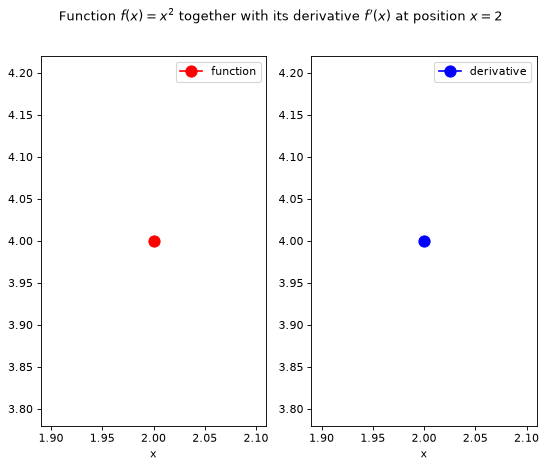

In [5]:
# Plot your solution
x, f_x = derivative_of_simple_function_at_position()

plot(x, f_x, True)

In [6]:
# Test your code

!python ./tests/test_derivatives_and_graphs.py --test_case TestDerivativeSimpleFunctionAtPosition

Running tests for Task 2.1 - Derivative of a Simple Function at a Specific Position...
--------------------------------------------------
[3 / 3] test(s) passed.
Score achieved: [1.0 / 1.0]
.
----------------------------------------------------------------------
Ran 1 test in 0.048s

OK


<a name='2-2'></a>
### 2.2 - Derivative of a More Complicated Function at a Specific Position \[1 point\] ###

Let's try what we have learned above for a more complicated function $g(x)$.
The function $g(x)$ is given as:
\begin{equation}
    g(x) = 2x^3 + x^2 + x
\end{equation}
And we want to calculate its derivative $g'(x)$ at position $x=5$.

> **TODO:**
> - Implement the method `derivative_of_more_complicated_function_at_position` which calculates the derivative of $g(x)$ at $x=5$.


In [7]:
def derivative_of_more_complicated_function_at_position():
    """
    Calculate the derivative g'(x) = (2x^3 + x^2 + x)' with respect to x at position x=5.

    :return: The function g(x) = 2x^3 + x^2 + x at x=5 as well as x.
    """

    x = None
    g_x = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Create x as a tensor with a single element which has the value 5.0  #
    #       which allows for the Pytorch gradient computation                   #
    #    2) Calculate g(x)                                                      #
    #    3) Calculate g'(x) with respect to x                                   #
    #############################################################################

    x = torch.tensor(5.0, requires_grad=True)
    g_x = 2 * x ** 3 + x ** 2 + x
    g_x.backward()
    

    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return x, g_x

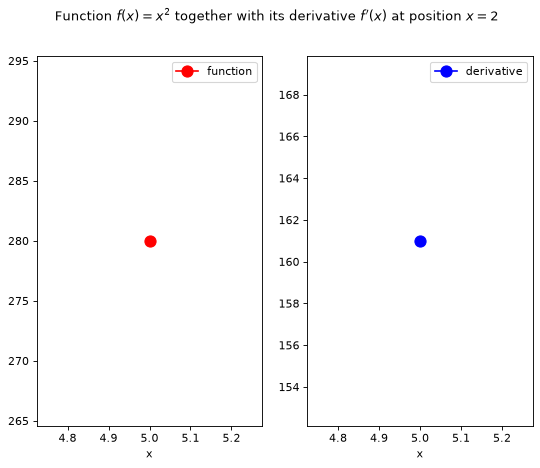

In [8]:
# Plot your solution
x, g_x = derivative_of_more_complicated_function_at_position()

plot(x, g_x, True)

In [9]:
# Test your code

!python ./tests/test_derivatives_and_graphs.py --test_case TestDerivativeComplicatedFunctionAtPosition

Running tests for Task 2.2 - Derivative of a More Complicated Function at a Specific Position...
--------------------------------------------------
[3 / 3] test(s) passed.
Score achieved: [1.0 / 1.0]
.
----------------------------------------------------------------------
Ran 1 test in 0.050s

OK


<a name='2-3'></a>
### 2.3 - Derivative of an Entire Function \[1.5 points\] ###

Having the derivative at a specific position $x^\star$ is cool, but in general we are interested in the derivative of an entire function.
Calculation of the latter can also be done quite fast by using the autograd functionality of Pytorch.

Let's take a look at the Rectified Linear Unit (ReLU) function which is given as:
\begin{equation}
    f(x) = max(0, x)
\end{equation}

We want to calculate the derivative of the entire function at every point of $x$.

> **TODO:**
> - Implement the method `derivative_of_relu` which calculates the derivative $f'(x)$ of $f(x)$ at every point in $x$.


> **Hints:**
> 1. Check out the *[sum()](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDL0110ENSkillsNetwork20647811-2022-01-01)*-trick provided by Pytorch to get the derivative of a vector valued function.


In [13]:
def derivative_of_relu():
    """
    Calculate the derivative of the relu function.

    :return: The relu function as well as x.
    """

    x = None
    f_x = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Create x as a tensor with 1000 values in between [-10, 10] which    #
    #       allows for the Pytorch gradient computation                         #
    #    2) Calculate the relu function f(x)                                    #
    #    3) Apply the sum()-trick provided by Pytorch                           #
    #    4) Calculate f'(x) with respect to x                                   #
    #############################################################################

    x = torch.linspace(-10, 10, 1000, requires_grad=True)
    F_x = torch.relu(x)
    # backward() needs a single number so sum first
    # every x only affects its own output, so x.grad still holds f'(x) for each point
    F_x.sum().backward()
  

    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return x, F_x

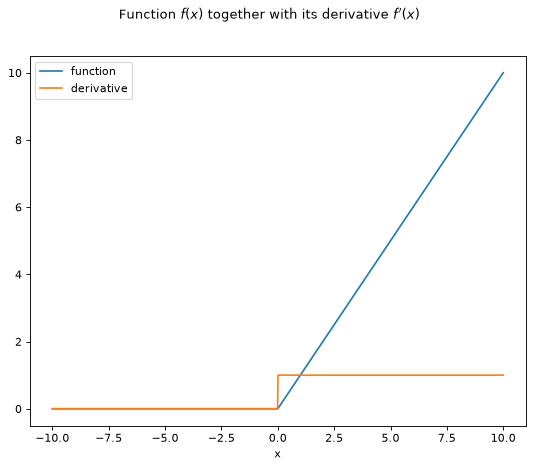

In [14]:
# Plot your solution
x, f_x = derivative_of_relu()

plot(x, f_x)

In [15]:
# Test your code

!python ./tests/test_derivatives_and_graphs.py --test_case TestDerivativeEntireFunction

Running tests for Task 2.3 - Derivative of an Entire Function...
--------------------------------------------------
[3 / 3] test(s) passed.
Score achieved: [1.5 / 1.5]
.
----------------------------------------------------------------------
Ran 1 test in 0.049s

OK


<a name='3'></a>
## 3 - Partial Derivatives \[2 points\] ##

In this exercise you will learn how to calculate partial derivatives of functions which do calculations based on Pytorch tensors.

Consider the function $f(x)$ given as:
\begin{equation}
    f(u, v) = v*u + u^2 + 3*v
\end{equation}
We want to calculate the derivatives $f_{u}$ and $f_{v}$ of $f(u, v)$ with respect to $u$ and $v$ respectively.

> **TODO:**
> - Implement the method `partial_derivatives` which calculates the derivatives $f_{u}$ and $f_{v}$ of $f(u, v)$ with respect to $u$ and $v$ respectively.


In [16]:
def partial_derivatives():
    """
    Calculate the partial derivatives f_u and f_v the function f(u, v) = v*u + u^2 + 3*v.

    :return: The function f(u, v) as well as u and v.
    """

    u = None
    v = None
    F_uv = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Create u as a tensor with 100 values in between [-10, 10] which     #
    #       allows for the Pytorch gradient computation                         #
    #    2) Create v as a tensor with 100 values in between [-10, 10] which     #
    #       allows for the Pytorch gradient computation                         #
    #    3) Calculate the function f(u, v)                                      #
    #    4) Apply the sum()-trick provided by Pytorch                           #
    #    5) Calculate f_u and f_v with respect to u and v respectively          #
    #############################################################################

    u = torch.linspace(-10, 10, 100, requires_grad=True)
    v = torch.linspace(-10, 10, 100, requires_grad=True)
    F_uv = v * u + u ** 2 + 3 * v
    # after this u.grad is f_u = v + 2u and v.grad is f_v = u + 3
    F_uv.sum().backward()
    
    

    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return u, v, F_uv

In [17]:
# Test your code

!python ./tests/test_derivatives_and_graphs.py --test_case TestPartialDerivatives

Running tests for Task 3 - Partial Derivatives...
--------------------------------------------------
[5 / 5] test(s) passed.
Score achieved: [2.0 / 2.0]
.
----------------------------------------------------------------------
Ran 1 test in 0.031s

OK


<a name='4'></a>
## 4 - End of Exercise ##